# Session 21 Solutions: Charts with Matplotlib

Data Science with Python, Level 2, Stage 3: Exploring Data

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")
bikes["date"] = pd.to_datetime(bikes["date"])

## In-Class Exercises

### In-Class Exercise 1: Temperature Over the Year

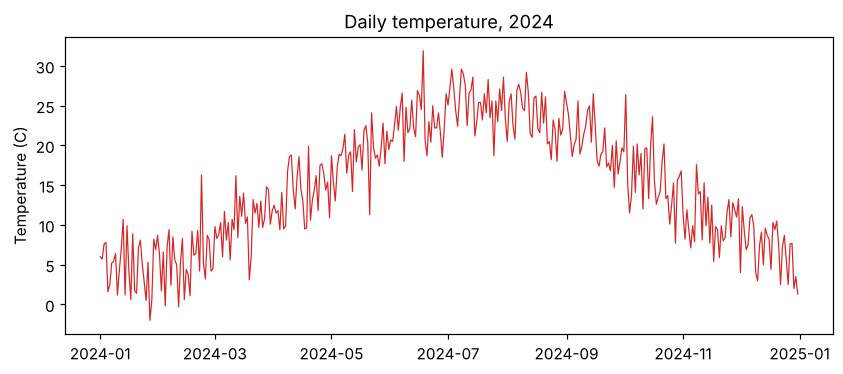

In [2]:
y24 = bikes[bikes["date"].dt.year == 2024]
plt.figure(figsize=(9, 3.5))
plt.plot(y24["date"], y24["temp_c"], linewidth=0.8, color="tab:red")
plt.title("Daily temperature, 2024")
plt.ylabel("Temperature (C)")
plt.show()

### In-Class Exercise 2: Working Days

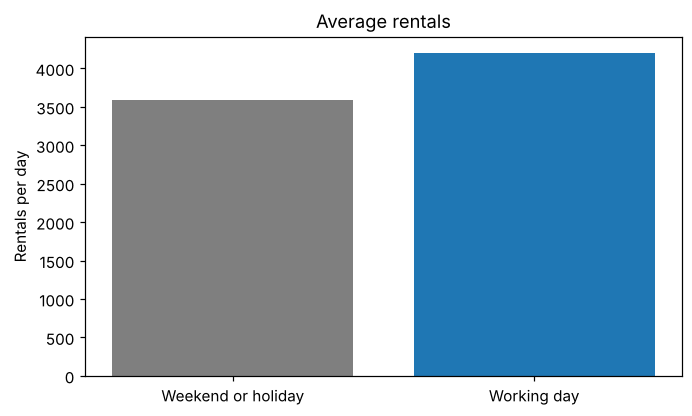

In [3]:
avg = bikes.groupby("working_day")["rentals"].mean()
plt.bar(["Weekend or holiday", "Working day"], avg.values, color=["tab:gray", "tab:blue"])
plt.title("Average rentals")
plt.ylabel("Rentals per day")
plt.show()

### In-Class Exercise 3: Wind and Rentals

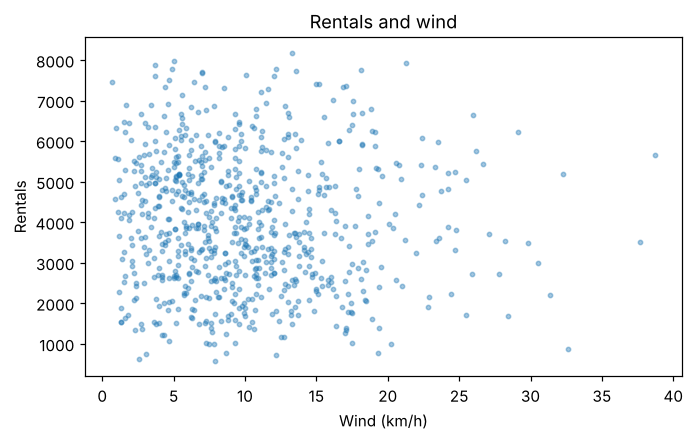

In [4]:
plt.scatter(bikes["wind_kmh"], bikes["rentals"], s=8, alpha=0.4)
plt.title("Rentals and wind")
plt.xlabel("Wind (km/h)")
plt.ylabel("Rentals")
plt.show()

### In-Class Exercise 4: Two Years Compared

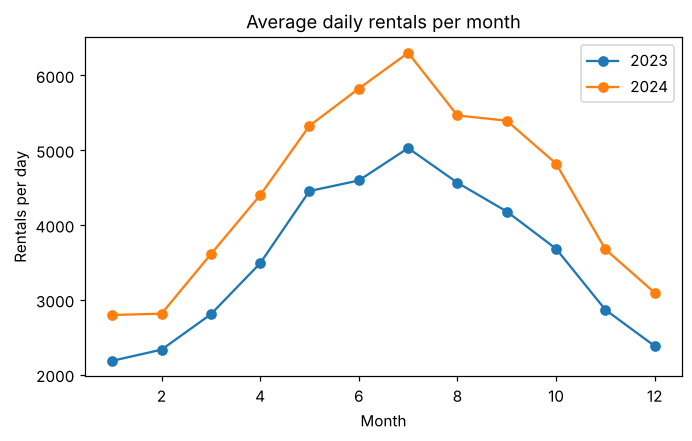

In [5]:
for year in [2023, 2024]:
    part = bikes[bikes["date"].dt.year == year]
    m = part.groupby(part["date"].dt.month)["rentals"].mean()
    plt.plot(m.index, m.values, marker="o", label=str(year))
plt.title("Average daily rentals per month")
plt.xlabel("Month")
plt.ylabel("Rentals per day")
plt.legend()
plt.show()

## Part A: Basic

### Exercise 1: Simple Line Chart

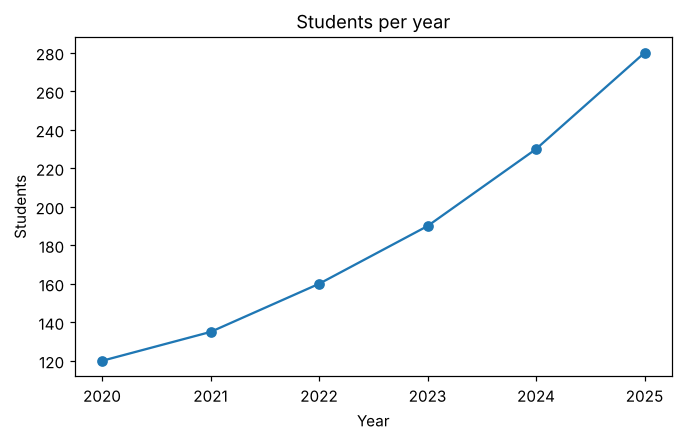

In [6]:
years = [2020, 2021, 2022, 2023, 2024, 2025]
students = [120, 135, 160, 190, 230, 280]
plt.plot(years, students, marker="o")
plt.title("Students per year")
plt.xlabel("Year")
plt.ylabel("Students")
plt.show()

### Exercise 2: Cafe Bar Chart

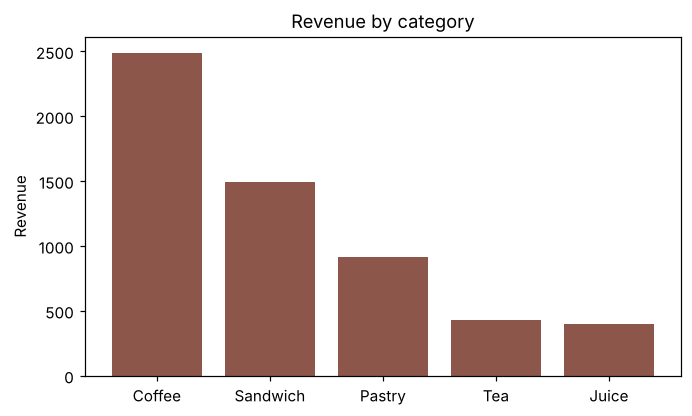

In [7]:
cafe = pd.read_csv(DATA_URL + "cafe_sales.csv")
cafe["revenue"] = cafe["unit_price"] * cafe["quantity"]
by_cat = cafe.groupby("category")["revenue"].sum().sort_values(ascending=False)
plt.bar(by_cat.index, by_cat.values, color="tab:brown")
plt.title("Revenue by category")
plt.ylabel("Revenue")
plt.show()

## Part B: Intermediate

### Exercise 3: Exam Scores

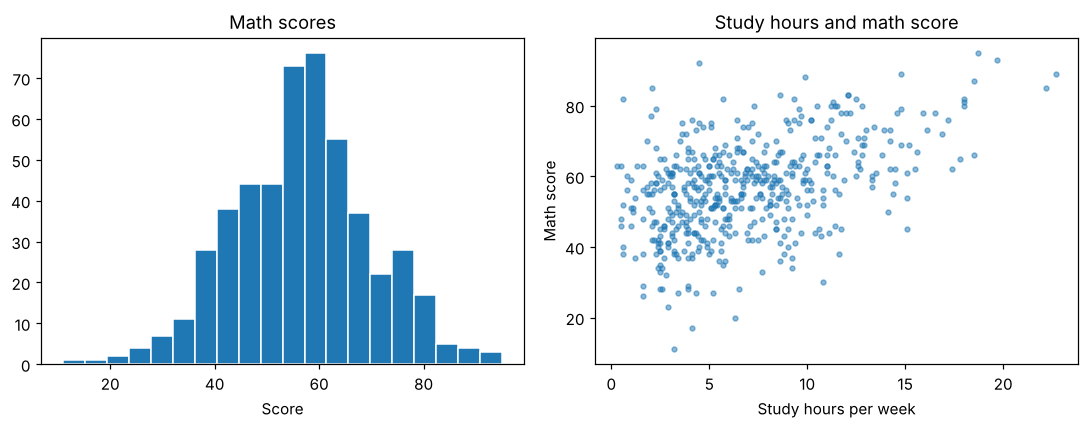

In [8]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(exams["math"], bins=20, edgecolor="white")
axes[0].set_title("Math scores")
axes[0].set_xlabel("Score")
axes[1].scatter(exams["study_hours_week"], exams["math"], s=10, alpha=0.5)
axes[1].set_title("Study hours and math score")
axes[1].set_xlabel("Study hours per week")
axes[1].set_ylabel("Math score")
fig.tight_layout()
plt.show()

### Exercise 4: Weather of Two Cities

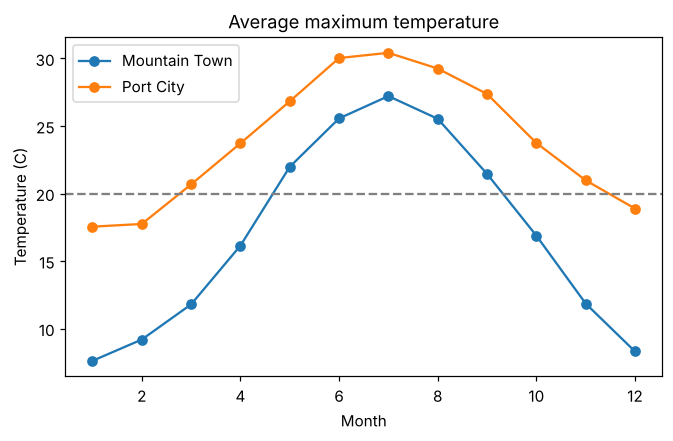

In [9]:
w = pd.read_csv(DATA_URL + "weather_2024.csv")
w["month"] = pd.to_datetime(w["date"]).dt.month
for city, part in w.groupby("city"):
    m = part.groupby("month")["temp_max"].mean()
    plt.plot(m.index, m.values, marker="o", label=city)
plt.axhline(20, linestyle="--", color="gray")
plt.title("Average maximum temperature")
plt.xlabel("Month")
plt.ylabel("Temperature (C)")
plt.legend()
plt.show()

## Part C: Challenge

### Exercise 5: A Four-Chart Dashboard

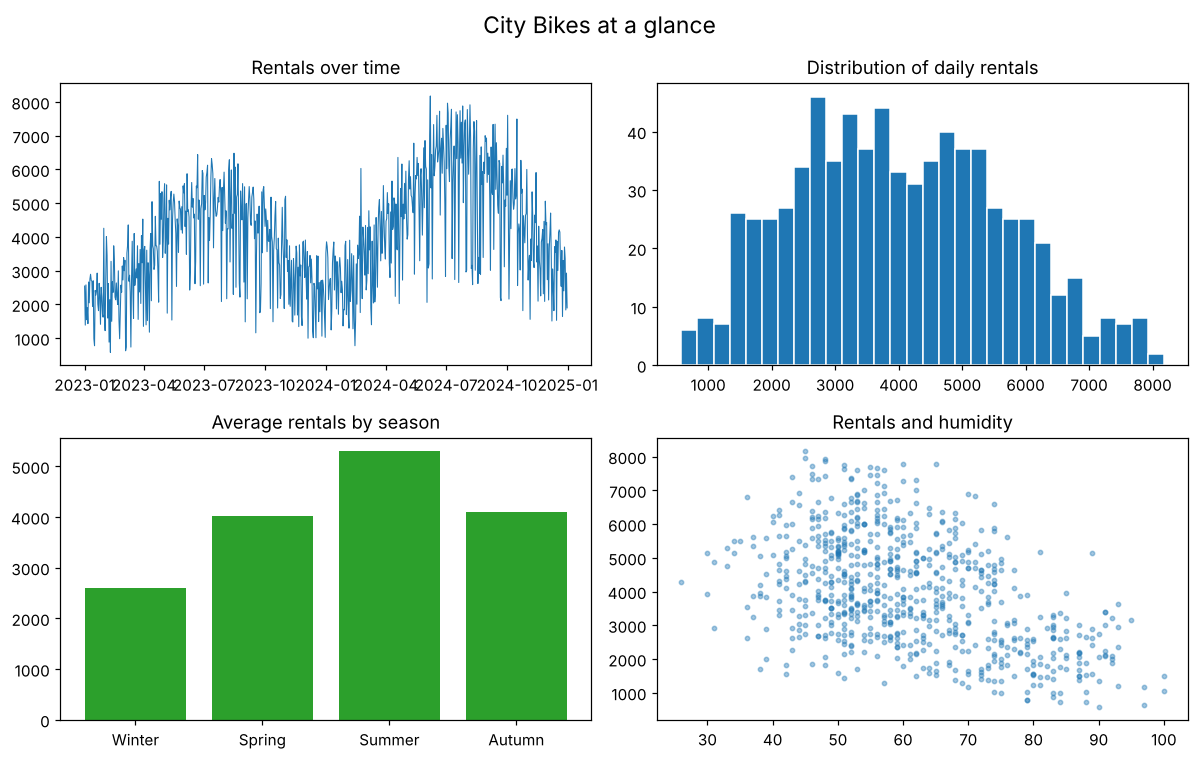

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].plot(bikes["date"], bikes["rentals"], linewidth=0.7)
axes[0, 0].set_title("Rentals over time")
axes[0, 1].hist(bikes["rentals"], bins=30, edgecolor="white")
axes[0, 1].set_title("Distribution of daily rentals")
season = bikes.groupby("season")["rentals"].mean().reindex(["Winter", "Spring", "Summer", "Autumn"])
axes[1, 0].bar(season.index, season.values, color="tab:green")
axes[1, 0].set_title("Average rentals by season")
axes[1, 1].scatter(bikes["humidity"], bikes["rentals"], s=8, alpha=0.4)
axes[1, 1].set_title("Rentals and humidity")
fig.suptitle("City Bikes at a glance", fontsize=15)
fig.tight_layout()
fig.savefig("bikes_dashboard.png", dpi=120)
plt.show()

## Part D: Cumulative Project: City Bikes

### Exercise 6: City Bikes: First Questions

          date  temp_c  wind_kmh  rentals
209 2023-07-29    20.4       1.9     4187
258 2023-09-16    22.9      19.4     4473
275 2023-10-03    20.8      11.8     4505


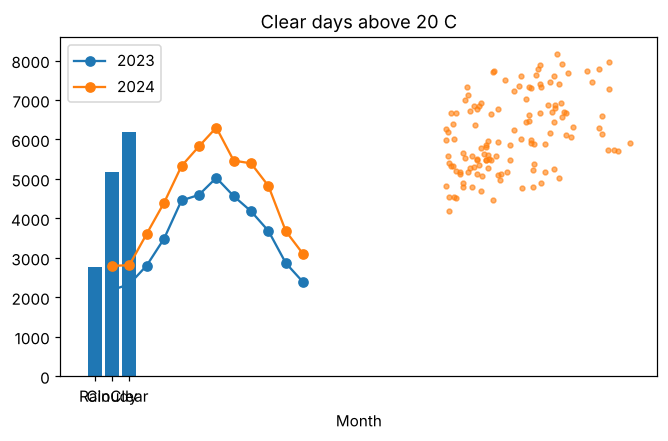

In [11]:
for year in [2023, 2024]:
    part = bikes[bikes["date"].dt.year == year]
    m = part.groupby(part["date"].dt.month)["rentals"].mean()
    plt.plot(m.index, m.values, marker="o", label=str(year))
plt.title("Monthly average rentals")
plt.xlabel("Month")
plt.legend()
plt.show()
# Rentals in 2024 are clearly higher than in 2023 in every month.

summer = bikes[bikes["season"] == "Summer"].groupby("weather")["rentals"].mean().sort_values()
plt.bar(summer.index, summer.values)
plt.title("Average summer rentals by weather")
plt.show()
# Rain roughly halves summer rentals compared with clear days.

clear_warm = bikes[(bikes["weather"] == "Clear") & (bikes["temp_c"] > 20)]
plt.scatter(clear_warm["temp_c"], clear_warm["rentals"], s=10, alpha=0.6)
plt.title("Clear days above 20 C")
plt.show()
print(clear_warm.nsmallest(3, "rentals")[["date", "temp_c", "wind_kmh", "rentals"]])
# The lowest clear warm days are mostly windy days or early 2023 days, before the growth.

## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | Line charts show change over time. |
| 2 | B | A histogram counts values in ranges called bins. |
| 3 | B | The length of a bar is read as the size of the value. |
| 4 | B | The three charts are `axes[0]`, `axes[1]` and `axes[2]`. |
| 5 | B | Transparent dots show where many points overlap. |